# General Online Surrogate Experiment

This notebook runs the final online-data surrogate experiments for the filter, inductor, and transmission-line cases. Select any compatible `*_online*_final.yaml` preset, then load or train the matching MLP/TCN/BNN model using the same training and evaluation flow as `scripts/legacy/bnn_script_demo.py`.

In [7]:
from pathlib import Path
import os
import random
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
import yaml
from torch import nn, optim

NOTEBOOK_DIR = Path.cwd()
REPO_ROOT = NOTEBOOK_DIR if (NOTEBOOK_DIR / "src").exists() else NOTEBOOK_DIR.parent
os.chdir(REPO_ROOT)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src import (
    BKLLoss,
    DictConfig,
    DivideRegularizer,
    MinMaxRegularizer,
    MultiOutputBNN,
    MultiOutputMLP,
    MultiOutputTCN,
    NoneRegularizer,
    SPDataset,
    SPOnlineDataset,
    fitted_error_estimate,
    train,
    validate,
)

Path("models").mkdir(exist_ok=True)
Path("final").mkdir(exist_ok=True)

print(f"Repo root: {REPO_ROOT}")

Repo root: /home/zhanghf/projects/vector


## Select Experiment Config

Choose one preset from `AVAILABLE_CONFIGS`, or set `CONFIG_PATH` directly. By default the notebook loads an existing model checkpoint if present. Set `RETRAIN = True` to rerun the training defined by the selected YAML.

In [8]:
AVAILABLE_CONFIGS = {
    path.stem: path
    for path in sorted(Path("configs").glob("*_online*_final.yaml"))
}

# Examples:
# SELECTED_CONFIG = "filter_tcn_online_uaw_uniform_final"
# SELECTED_CONFIG = "filter_tcn_online_random_uaw_final"
# SELECTED_CONFIG = "filter_tcn_online_random_uniform_final"

# SELECTED_CONFIG = "filter_mlp_online_uaw_uaw_final"
# SELECTED_CONFIG = "filter_mlp_online_random_uaw_final"
# SELECTED_CONFIG = "filter_mlp_online_random_uniform_final"

# SELECTED_CONFIG = "inductor_mlp_online_uaw_uaw_final"
# SELECTED_CONFIG = "inductor_mlp_online_random_uaw_final"
# SELECTED_CONFIG = "inductor_mlp_online_random_uniform_final"

# SELECTED_CONFIG = "line_tcn_online_uaw_uaw_final"
# SELECTED_CONFIG = "line_tcn_online_random_uaw_final"
# SELECTED_CONFIG = "line_tcn_online_random_uniform_final"

# SELECTED_CONFIG = "line_mlp_online_uaw_uaw_final"
# SELECTED_CONFIG = "line_mlp_online_random_uaw_final"
# SELECTED_CONFIG = "line_mlp_online_random_uniform_final"


SELECTED_CONFIG = "inductor_mlp_online_uaw_uaw_final"

CONFIG_PATH = AVAILABLE_CONFIGS[SELECTED_CONFIG]
RETRAIN = False
SEED = 42

# Keep this as None for the exact YAML value. Set an int, e.g. 20, for a smoke run.
EPOCH_OVERRIDE = None


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def load_experiment_config(config_path):
    with config_path.open("r") as f:
        raw_config = yaml.safe_load(f)
    if EPOCH_OVERRIDE is not None:
        raw_config["train"]["epochs"] = EPOCH_OVERRIDE
    config = DictConfig(raw_config)
    config.retrain = RETRAIN
    return config


def resolve_existing_path(path_value):
    path = Path(path_value)
    if path.exists():
        return path

    # Several legacy configs store the original cluster path. Prefer the
    # same filename from this checkout's data directory when available.
    local_data_path = REPO_ROOT / "data" / path.name
    if local_data_path.exists():
        return local_data_path

    return path


seed_everything(SEED)
print("Available configs:")
for name in AVAILABLE_CONFIGS:
    print(f"  {name}")
print(f"\nSelected config: {CONFIG_PATH}")
config = load_experiment_config(CONFIG_PATH)
config.data.load_data_path = str(resolve_existing_path(config.data.load_data_path))
config

Available configs:
  filter_mlp_online_random_uaw_final
  filter_mlp_online_random_uniform_final
  filter_mlp_online_uaw_uaw_final
  filter_tcn_online_random_uaw_final
  filter_tcn_online_random_uniform_final
  filter_tcn_online_uaw_uaw_final
  filter_tcn_online_uaw_uniform_final
  inductor_mlp_online_random_uaw_final
  inductor_mlp_online_random_uniform_final
  inductor_mlp_online_uaw_uaw_final
  line_mlp_online_random_uaw_final
  line_mlp_online_random_uniform_final
  line_mlp_online_uaw_uaw_final
  line_tcn_online_random_uaw_final
  line_tcn_online_random_uniform_final
  line_tcn_online_uaw_uaw_final

Selected config: configs/inductor_mlp_online_uaw_uaw_final.yaml


{'target': {'name': 'inductor',
  'port_num': 2,
  'port_combinations': [[0, 0], [0, 1]]},
 'data': {'path': 'data/spiral_inductor_export',
  'start_idx': 4,
  'freqs': {'min': 100000000.0, 'max': 20020000000.0, 'step': 30000000.0},
  'regularization': {'min': [55, 1.5, 15.0, 100000000.0],
   'max': [60, 2.0, 20.0, 19990000000.0]},
  'mode': 'ri',
  'load_from_online_data': True,
  'load_data_path': '/home/zhanghf/projects/vector/data/inductor_bnn_online_uaw_uaw_dataset.pkl'},
 'model': {'name': 'mlp',
  'input_dim': 4,
  'hidden_dims': [256, 256, 256],
  'output_channels': {'r': [2, 1], 'i': [2, 1]}},
 'case_name': 'inductor_mlp_online_uaw_uaw_final',
 'train': {'epochs': 5000},
 'test': {'samples': 100},
 'retrain': False}

## Experiment Runner

In [9]:
class OnlineSurrogateExperiment:
    def __init__(self, config):
        self.config = config
        self.freqs = np.arange(config.data.freqs.min, config.data.freqs.max, config.data.freqs.step)
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.train_dataset, self.test_dataset = self._build_datasets()
        self.train_loader = torch.utils.data.DataLoader(self.train_dataset, batch_size=32, shuffle=True)
        self.test_loader = torch.utils.data.DataLoader(self.test_dataset, batch_size=1, shuffle=False)
        self.model_path = Path(f"models/{config.case_name}.pth")
        self.net, self.bayesian_loss_fn, self.bayesian_loss_weight = self._build_model()
        self.regularizer = self._build_regularizer()
        self.optimizer = optim.Adam(self.net.parameters(), lr=0.0001)

    def _build_datasets(self):
        if self.config.data.load_from_online_data:
            test_idx_path = self._resolve_test_idx_path()
            if not Path(self.config.data.load_data_path).exists():
                raise FileNotFoundError(f"Missing online dataset pickle: {self.config.data.load_data_path}")

            test_idx = np.load(test_idx_path)

            train_dataset = SPOnlineDataset(
                self.config.data.path,
                self.freqs,
                self.config.target.port_num,
                self.config.data.start_idx,
                self.config.target.port_combinations,
                self.config.data.mode,
            )
            train_dataset.load(self.config.data.load_data_path)
            train_dataset.set_sample_idx(train_dataset.history_idx)

            test_dataset = SPOnlineDataset(
                self.config.data.path,
                self.freqs,
                self.config.target.port_num,
                self.config.data.start_idx,
                self.config.target.port_combinations,
                self.config.data.mode,
            )
            test_dataset.load(self.config.data.load_data_path)
            test_dataset.set_sample_idx(test_idx.tolist())
            return train_dataset, test_dataset

        dataset = SPDataset(
            self.config.data.path,
            self.freqs,
            self.config.target.port_num,
            self.config.data.start_idx,
            self.config.target.port_combinations,
            self.config.data.mode,
        )
        train_size = int(0.8 * len(dataset))
        test_size = len(dataset) - train_size
        train_dataset, test_dataset = torch.utils.data.random_split(
            dataset,
            [train_size, test_size],
            generator=torch.Generator().manual_seed(SEED),
        )
        test_dataset.random_sample = False
        return train_dataset, test_dataset

    def _resolve_test_idx_path(self):
        candidates = [Path(f"models/{self.config.target.name}_test_idx.npy")]
        if self.config.target.name == "transmission_line":
            candidates.append(Path("models/line_test_idx.npy"))
        for candidate in candidates:
            if candidate.exists():
                return candidate
        raise FileNotFoundError(
            "Missing test split file. Tried: "
            + ", ".join(str(candidate) for candidate in candidates)
        )

    def _build_model(self):
        model_name = self.config.model.name
        prior_mus = [0.0] * len(self.config.model.hidden_dims)
        prior_sigmas = [0.1] * len(self.config.model.hidden_dims)

        if model_name == "mlp":
            net = MultiOutputMLP(
                input_dim=self.config.model.input_dim,
                hidden_dims=self.config.model.hidden_dims,
                output_channels=self.config.model.output_channels,
            )
            return net, None, 0.0

        if model_name == "tcn":
            net = MultiOutputTCN(
                input_dim=self.config.model.input_dim,
                hidden_dims=self.config.model.hidden_dims,
                output_channels=self.config.model.output_channels,
                tcns=self.config.model.tcns,
            )
            return net, None, 0.0

        if model_name == "bnn":
            net = MultiOutputBNN(
                input_dim=self.config.model.input_dim,
                hidden_dims=self.config.model.hidden_dims,
                prior_mus=prior_mus,
                prior_sigmas=prior_sigmas,
                output_channels=self.config.model.output_channels,
            )
            return net, BKLLoss(reduction="mean", last_layer_only=False), 0.01

        raise ValueError(f"Unsupported model type: {model_name}")

    def _build_regularizer(self):
        x_regularizer = MinMaxRegularizer(
            self.config.data.regularization.min,
            self.config.data.regularization.max,
        )
        if "y_regularization" in self.config.data:
            y_regularizer = {
                "r": DivideRegularizer(self.config.data.y_regularization.r),
                "i": DivideRegularizer(self.config.data.y_regularization.i),
            }
        else:
            y_regularizer = {"r": NoneRegularizer(), "i": NoneRegularizer()}
        return x_regularizer, y_regularizer

    def fit_or_load(self):
        self.net.to(self.device)
        if self.model_path.exists() and not self.config.retrain:
            print(f"Loading existing model: {self.model_path}")
            self.net.load_state_dict(torch.load(self.model_path, map_location=self.device))
            self.net.eval()
            return

        print(f"Training {self.config.case_name} for {self.config.train.epochs} epochs")
        self.net, self.optimizer = train(
            epochs=self.config.train.epochs,
            dataloader=self.train_loader,
            model=self.net,
            optimizer=self.optimizer,
            data_loss_fns={"r": nn.MSELoss(), "i": nn.MSELoss()},
            data_loss_weights={"r": 1.0, "i": 1.0},
            bayesian_loss_fn=self.bayesian_loss_fn,
            bayesian_loss_weight=self.bayesian_loss_weight,
            regularizer=self.regularizer,
            device=self.device,
        )
        torch.save(self.net.state_dict(), self.model_path)
        self.net.eval()

    def _predict_batch(self, x, y):
        output = validate(x, y, self.net, self.regularizer, True, self.config.test.samples, self.device)
        y_np = {
            "r": y["r"].cpu().detach().numpy(),
            "i": y["i"].cpu().detach().numpy(),
        }

        if self._model_outputs_unflattened():
            output["r"] = output["r"].transpose(0, 2, 1)
            output["i"] = output["i"].transpose(0, 2, 1)
            y_np["r"] = y_np["r"].transpose(0, 2, 1)
            y_np["i"] = y_np["i"].transpose(0, 2, 1)

        output["ri"] = output["r"] + 1j * output["i"]
        y_np["ri"] = y_np["r"] + 1j * y_np["i"]
        output["ri_dB"] = 20 * np.log10(np.maximum(np.abs(output["ri"]), 1e-12))
        y_np["ri_dB"] = 20 * np.log10(np.maximum(np.abs(y_np["ri"]), 1e-12))
        return output, y_np

    def _model_outputs_unflattened(self):
        return self.config.model.name == "tcn" or self.config.data.mode == "unflatten_ri"

    def evaluate(self):
        self.net.eval()
        metrics = ["MSE", "RMSE", "R-squared", "PSNR"]
        statistics = {metric: [] for metric in metrics}

        with torch.no_grad():
            for x, y in self.test_loader:
                output, y_np = self._predict_batch(x, y)
                for metric in metrics:
                    statistics[metric].append(
                        fitted_error_estimate(y_np["ri_dB"], output["ri_dB"], method=metric, norm="range")
                    )

        return {metric: float(np.mean(values)) for metric, values in statistics.items()}

    def plot_prediction(self, sample_number=0, port_number=0):
        self.net.eval()
        with torch.no_grad():
            for idx, (x, y) in enumerate(self.test_loader):
                if idx == sample_number:
                    output, y_np = self._predict_batch(x, y)
                    break
            else:
                raise IndexError(f"sample_number {sample_number} is outside the test set")

        fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
        axes[0].plot(self.freqs, y_np["r"][0, :, port_number], label="true")
        axes[0].plot(self.freqs, output["r"][0, :, port_number], "--", label="predicted")
        axes[0].set_ylabel("Real")
        axes[0].legend()

        axes[1].plot(self.freqs, y_np["i"][0, :, port_number], label="true")
        axes[1].plot(self.freqs, output["i"][0, :, port_number], "--", label="predicted")
        axes[1].set_ylabel("Imag")
        axes[1].legend()

        axes[2].plot(self.freqs, np.abs(y_np["ri"])[0, :, port_number], label="true")
        axes[2].plot(self.freqs, np.abs(output["ri"])[0, :, port_number], "--", label="predicted")
        axes[2].set_xlabel("Frequency (Hz)")
        axes[2].set_ylabel("Magnitude")
        axes[2].legend()
        plt.tight_layout()
        return fig


## Run Or Load The Experiment

In [10]:
experiment = OnlineSurrogateExperiment(config)
print(f"Device: {experiment.device}")
print(f"Online dataset: {config.data.load_data_path}")
print(f"Train samples: {len(experiment.train_dataset)}")
print(f"Test samples: {len(experiment.test_dataset)}")
print(f"Model path: {experiment.model_path}")

experiment.fit_or_load()

Loading dataset: 100%|██████████| 792/792 [00:00<00:00, 57443.30file/s]

Device: cuda
Online dataset: /home/zhanghf/projects/vector/data/inductor_bnn_online_uaw_uaw_dataset.pkl
Train samples: 150
Test samples: 79
Model path: models/inductor_mlp_online_uaw_uaw_final.pth
Loading existing model: models/inductor_mlp_online_uaw_uaw_final.pth


## Evaluate

In [11]:
metrics = experiment.evaluate()
metrics

{'MSE': 0.5457335114479065,
 'RMSE': 0.696811318397522,
 'R-squared': 0.9900208711624146,
 'PSNR': 34.42095947265625}

## Plot One Test Prediction

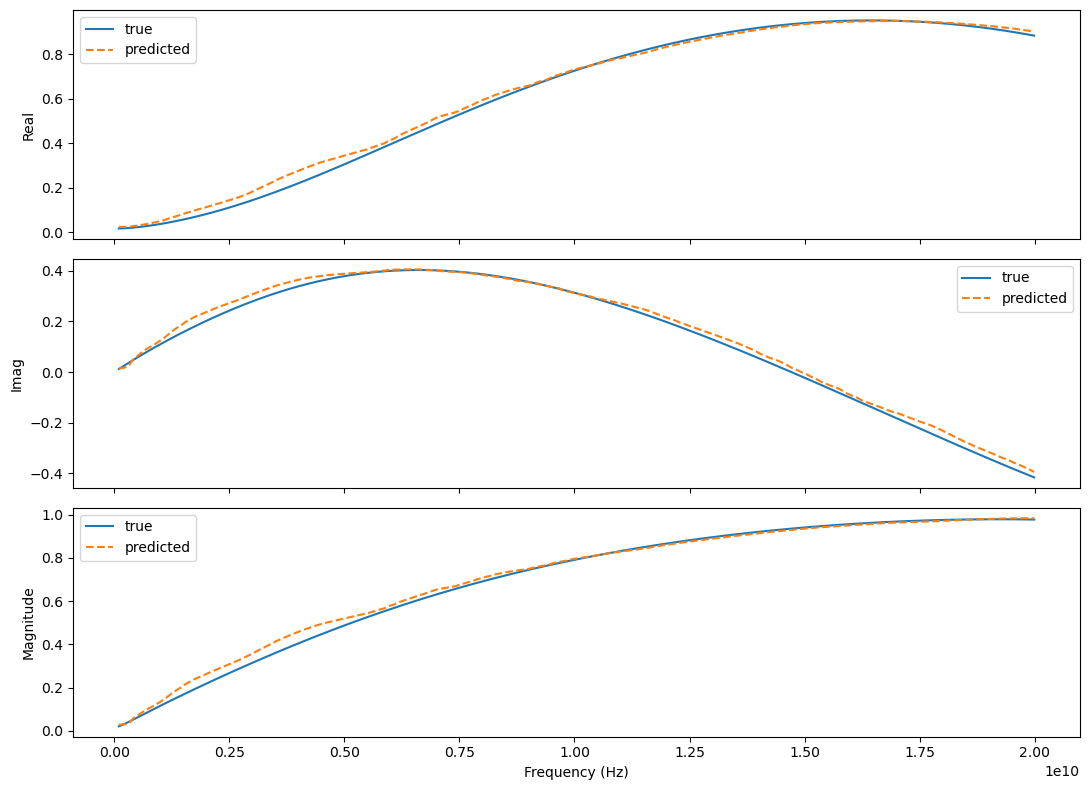

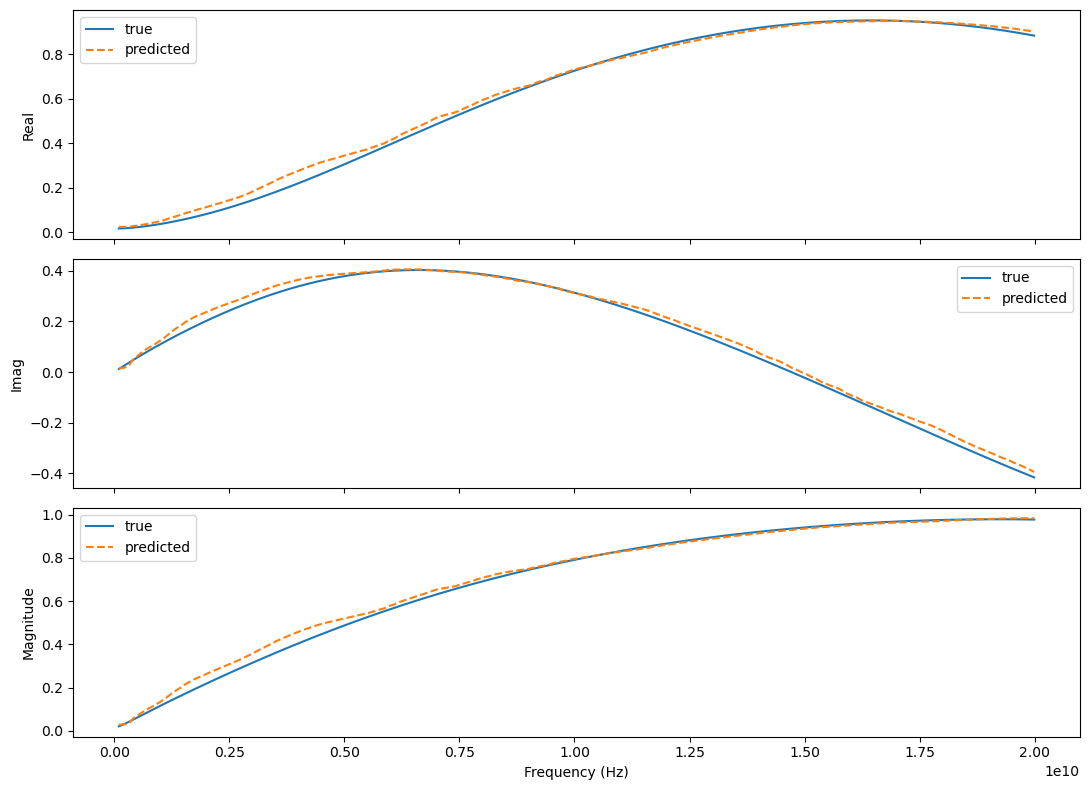

In [12]:
experiment.plot_prediction(sample_number=0, port_number=0)